# 1. Провожу EDA.
Создаю отдельный датасет с подтвержденным фродом


In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('transactions.csv')
df_frod_confirmed = df[df['target'] == 1]

## Общий обзор


In [3]:
print("Размер таблицы", df.shape)
print("Размер таблицы фрод", df_frod_confirmed.shape)

print(df["target"].value_counts(dropna=False))
print(df_frod_confirmed["target"].value_counts(dropna=False))

print("\nПовторы txn_id:", df["txn_id"].duplicated().sum())


Размер таблицы (199768, 18)
Размер таблицы фрод (1500, 18)
target
NaN    198268
1.0      1500
Name: count, dtype: int64
target
1.0    1500
Name: count, dtype: int64

Повторы txn_id: 0


In [4]:
# Пропуски
print(df.isna().sum())

txn_id                     0
ts                         0
type                       0
amount                     0
mcc                    46224
mcc_name               46224
merchant_id            46224
merchant_name          46224
channel                    0
status                     0
device_id              31552
ip_country                 0
client_id                  0
segment                    0
account_age_months         0
home_country               0
counterparty_id       153544
target                198268
dtype: int64


Оставлю около 20% более поздних операций для проверки итоговой оценки.

In [5]:
df["ts"] = pd.to_datetime(df["ts"])
before = len(df[df["ts"] < "2026-10-22"])
from_ = len(df[df["ts"] >= "2026-10-22"])


print("До 22 ", before, "операции -", round(before / len(df) * 100, 2), "%")
print("С 22 ", from_, "операции -", round(from_ / len(df) * 100, 2), "%")

До 22  159024 операции - 79.6 %
С 22  40744 операции - 20.4 %


Получается примерно 80% для исследования и 20% для проверки. Поэтому использую 22 октября как границу. 

In [6]:
eda = df[df["ts"] < "2026-10-22"].copy()

Сравниваю суммы операций и возраст счетов у подтвержденного фрода и операций с неизвестным результатом.

In [7]:
print(eda.groupby("target", dropna=False)["amount"].describe().round(2))
print(eda.groupby("target", dropna=False)["account_age_months"].describe().round(2))
# Медиана - 14345 у фрода и 2125 у неподтвержденной транзакции. По возрасту счетов пока ниче не ясно, но фродовые как правило моложе.

           count      mean       std   min     25%      50%      75%       max
target                                                                        
1.0       1229.0  19950.02  23744.88  45.0  4590.0  14345.0  28000.0  302517.0
NaN     157795.0   5027.43  11384.06  45.0  1000.0   2125.0   4899.0  633742.0
           count   mean    std  min   25%   50%   75%    max
target                                                      
1.0       1229.0  48.51  69.03  0.0   8.0  24.0  61.0  600.0
NaN     157795.0  50.93  67.63  0.0  12.0  29.0  62.0  600.0


Смотрю, где подтвержденный фрод встречается чаще: по типу операции, каналу, статусу, сегменту клиента, стране и категории магазина. Сравниваю долю подтвержденных случаев и количество операций в группе

In [8]:
eda["foreign_ip"] = eda["ip_country"] != eda["home_country"]

for column in ["type", "channel", "status","segment","ip_country","foreign_ip","mcc_name"]:
    table = eda.groupby(column, dropna=False).agg(operations=("txn_id", "count"), confirmed=("target", "count"))
    table["confirmed_pct"] = table["confirmed"] / table["operations"] * 100
    print("\n", column)
    print(table.sort_values("confirmed_pct", ascending=False).round(2))
# Иностранный IP и категория «Антиквариат и искусство» связаны с повышенной долей подтвержденного фрода
# Дополнительными кандидатами для правил являются отклонённый статус и канал web


 type
              operations  confirmed  confirmed_pct
type                                              
purchase          122325        963           0.79
transfer_out       36699        266           0.72

 channel
            operations  confirmed  confirmed_pct
channel                                         
web              34876        562           1.61
mobile_app       99067        667           0.67
pos              25081          0           0.00

 status
          operations  confirmed  confirmed_pct
status                                        
declined        5030        203           4.04
approved      153994       1026           0.67

 segment
           operations  confirmed  confirmed_pct
segment                                        
premium          9922        135           1.36
mass_plus       33147        261           0.79
mass            97077        718           0.74
affluent        18878        115           0.61

 ip_country
            operations  co

Проверяю, в какие часы доля известного фрода выше.

      operations  confirmed  confirmed_pct
hour                                      
0            823         19           2.31
1           1014         83           8.19
2            887         86           9.70
3            829         75           9.05
4            883        101          11.44
5           1098         82           7.47
6           1467         19           1.30
7           3314         23           0.69
8           6495         37           0.57
9           9167         49           0.53
10          9957         60           0.60
11         10054         60           0.60
12          9561         52           0.54
13          8781         48           0.55
14          9731         40           0.41
15         10824         51           0.47
16         12165         52           0.43
17         13624         55           0.40
18         12778         58           0.45
19         11802         56           0.47
20          9913         53           0.53
21         

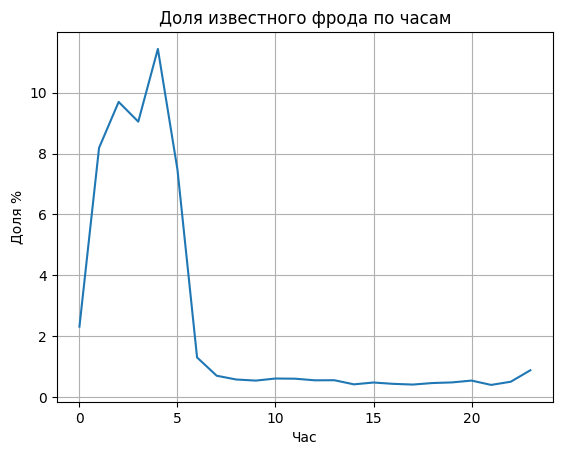

In [9]:
eda["hour"] = eda["ts"].dt.hour
by_hour = eda.groupby("hour").agg(operations=("txn_id", "count"), confirmed=("target", "count"))
by_hour["confirmed_pct"] = by_hour["confirmed"] / by_hour["operations"] * 100
print(by_hour.round(2))
print(by_hour["confirmed_pct"].plot(title="Доля известного фрода по часам", xlabel="Час", ylabel="Доля %", grid=True))
# Ночью доля подтвержденного фрода среди операций выше, особенно с 1 до 5 часов. Максимальная доля наблюдается
# в 4 часа - 11,44%. Время операции можно рассматривать как дополнительный признак подозрительности.

Сравню сумму операции с медианой предыдущих операций клиента. Гипотеза: подтвержденные случаи отличаются необычной суммой относительно привычных операций клиента?

In [10]:
eda = eda.sort_values(["client_id", "ts"], kind="stable").copy() # сортируем по клиенту и времени
eda["past_count"] = eda.groupby(["client_id", "type"]).cumcount()


eda["past_median"] = eda.groupby(["client_id", "type"])["amount"].transform(lambda x: x.shift().expanding().median())
eda["amount_/_median"] = eda["amount"] / eda["past_median"]
eda["has_history"] = eda["past_count"] >= 3

print("С историей от 3 операций:", round(eda["has_history"].mean()*100,2), "%")

print(eda[eda["has_history"]].groupby(["type", "target"], dropna=False)["amount_/_median"].describe().round(2))
#В подтвержденных мошеннических покупках сумма чаще превышает привычный уровень клиента. 
# Для переводов различие выражено слабее. Отношение суммы к медиане предыдущих покупок рассмотрю как дополнительный признак подозрительности


С историей от 3 операций: 54.13 %
                       count  mean    std   min   25%   50%   75%     max
type         target                                                      
purchase     1.0       619.0  8.96  32.11  0.02  0.97  2.89  8.50  657.05
             NaN     74466.0  2.33   5.96  0.01  0.48  0.97  2.13  366.12
transfer_out 1.0       174.0  1.70   1.58  0.28  0.80  1.19  2.01   12.04
             NaN     10813.0  1.38   1.47  0.03  0.57  1.00  1.71   61.82


Проверю, отличается ли доля подтверждений при новом устройстве или новом получателе. Сравниваю операции клиентов, у которых уже есть хотя бы 3 предыдущие операции.

In [11]:
eda["past_operations"] = eda.groupby("client_id").cumcount()
eda["new_device"] = ~eda.duplicated(["client_id", "device_id"])
eda["new_recipient"] = ~eda.duplicated(["client_id", "counterparty_id"])

for column, entity in [("new_device", "device_id"), ("new_recipient", "counterparty_id")]:
    sample = eda[(eda["past_operations"] >= 3) & eda[entity].notna()]
    table = sample.groupby(["type", column]).agg(operations=("txn_id", "count"), confirmed=("target", "count"))
    table["confirmed_pct"] = table["confirmed"] / table["operations"] * 100
    print("\n", column)
    print(table.round(2))

# В покупках новое устройство - полезный сигнал. Сам по себе перевод новому получателю - слабое основание для высокой оценки подозрительности, 
# но его можно учитывать в совокупности с остальными


 new_device
                         operations  confirmed  confirmed_pct
type         new_device                                      
purchase     False            62669        508           0.81
             True              3531        166           4.70
transfer_out False            24345        215           0.88
             True               716          8           1.12

 new_recipient
                            operations  confirmed  confirmed_pct
type         new_recipient                                      
transfer_out False                7224          0           0.00
             True                17837        223           1.25


Проверю связаны ли хотя бы 3 предыдущие операции клиента за последний час с повышенным фродом

In [12]:
third_previous = eda.groupby("client_id")["ts"].shift(3)
eda["many_operations"] = (eda["ts"] - third_previous) < pd.Timedelta(hours=1) # работает, так как eda отсортирована по клиенту и времени

table = eda.groupby(["type", "many_operations"]).agg(operations=("txn_id", "count"), confirmed=("target", "count"))
table["confirmed_pct"] = table["confirmed"] / table["operations"] * 100
print(table.round(2).to_string())
# В покупках после хотя бы 3 операций за час доля подтверждений - 28,55%, иначе - 0,60%.
# В переводах это условие встречается всего 9 раз, данных для вывода недостаточно

                              operations  confirmed  confirmed_pct
type         many_operations                                      
purchase     False                121502        728           0.60
             True                    823        235          28.55
transfer_out False                 36690        266           0.72
             True                      9          0           0.00


Проверю сочетание иностранного IP и ночного времени. 

In [13]:
eda["night"] = eda["hour"].isin([1, 2, 3, 4, 5])
table = eda.groupby(["foreign_ip", "night"]).agg(operations=("txn_id", "count"), confirmed=("target", "count"))
table["confirmed_pct"] = table["confirmed"] / table["operations"] * 100
print(table.round(2))
#Сочетание иностранного IP и ночного времени - крайне сильный признак

                  operations  confirmed  confirmed_pct
foreign_ip night                                      
False      False      149549        399           0.27
           True         3728        143           3.84
True       False        4764        403           8.46
           True          983        284          28.89


Сравню два способа отбора: по самой большой сумме и по самому большому превышению медианы

In [14]:
for operation_type in ["purchase", "transfer_out"]:
    sample = eda[(eda["type"] == operation_type) & eda["has_history"]]
    print(len(eda),len(sample))
    count = round(len(sample) * 0.1) # доля операций, которые отбираю для сравнения(чтобы не сравнить весь список со всем списком)

    by_amount = sample.sort_values("amount", ascending=False, kind="stable").head(count)
    by_ratio = sample.sort_values("amount_/_median", ascending=False, kind="stable").head(count)
    
    print(operation_type, "проверяем", count, "операций")
    print("Подтверждений по сумме:", by_amount["target"].count(), "по превышению медианы:", by_ratio["target"].count())
    # большая сумма находит больше подтверждений, чем превышение медианы

159024 75085
purchase проверяем 7508 операций
Подтверждений по сумме: 275 по превышению медианы: 239
159024 10987
transfer_out проверяем 1099 операций
Подтверждений по сумме: 123 по превышению медианы: 25


Сравню несколько границ количества операций за час

In [15]:
for threshold in [2, 3, 5]:
    previous = eda.groupby("client_id")["ts"].shift(threshold)
    eda["activity"] = (eda["ts"] - previous) < pd.Timedelta(hours=1)
    table = eda.groupby(["type", "activity"]).agg(operations=("txn_id", "count"), confirmed=("target", "count"))
    table["confirmed_pct"] = table["confirmed"] / table["operations"] * 100
    print("\nПредыдущих операций за час от", threshold)
    print(table.round(2).to_string())

# выберу порог 3 




Предыдущих операций за час от 2
                       operations  confirmed  confirmed_pct
type         activity                                      
purchase     False         121235        713           0.59
             True            1090        250          22.94
transfer_out False          36603        259           0.71
             True              96          7           7.29

Предыдущих операций за час от 3
                       operations  confirmed  confirmed_pct
type         activity                                      
purchase     False         121502        728           0.60
             True             823        235          28.55
transfer_out False          36690        266           0.72
             True               9          0           0.00

Предыдущих операций за час от 5
                       operations  confirmed  confirmed_pct
type         activity                                      
purchase     False         121621        762           0.63
 

В антиквариате самая высокая доля подтверждений среди категорий магазинов. Проверю, распределены ли подтверждения между магазинами или все относятся к одному.

In [16]:
sample = eda[eda["mcc_name"] == "Антиквариат и искусство"]
table = sample.groupby(["merchant_id", "merchant_name"]).agg(operations=("txn_id", "count"), confirmed=("target", "count"))
table["confirmed_pct"] = table["confirmed"] / table["operations"] * 100
print(table.round(2))
# Доли близкие. Значит, высокая доля подтверждений в категории не объясняется одним магазином.

                           operations  confirmed  confirmed_pct
merchant_id merchant_name                                      
m3803b4     Argent #1             221         29          13.12
ma2bca7     Bastion #2            243         30          12.35


## Аномалии

Посмотрю аномалии без использования target: самые большие превышения привычной суммы и самые плотные серии. 

In [17]:
for operation_type in ["purchase", "transfer_out"]:
    sample = eda[(eda["type"] == operation_type) & eda["has_history"]]
    print("\n", operation_type)
    print(sample.sort_values("amount_/_median", ascending=False).head()[["txn_id", "client_id", "ts", "amount", "past_count", "past_median", "amount_/_median"]].round(2))

eda["seconds_since_third_previous"] = (eda["ts"] - eda.groupby("client_id")["ts"].shift(3)).dt.total_seconds()
print("\nСамые короткие промежутки между текущей и третьей предыдущей операцией, секунды")
print(eda.sort_values("seconds_since_third_previous").head()[["txn_id", "client_id", "ts", "type", "amount", "seconds_since_third_previous"]].round(2))
print("Превышение медианы в 10 раз и больше:", (eda["has_history"] & (eda["amount_/_median"] >= 10)).sum())
print("Хотя бы 4 операции за 300 секунд:", (eda["seconds_since_third_previous"] <= 300).sum())


 purchase
                  txn_id   client_id                  ts  amount  past_count  \
12404   0fd1e16e8f836a64  b1b5c4a432 2026-10-17 09:46:22  125496          26   
20290   19c763f2e9c47403  834517349e 2026-10-08 17:47:20   40273          12   
1452    01f2ea95b59aeaa1  22628e1285 2026-10-01 08:21:56   48242          30   
41340   35294d861428ec36  74b284c007 2026-09-28 05:42:03   37818          29   
120604  9a2cda703a1b2e5f  834517349e 2026-10-19 17:16:55   33427          14   

        past_median  amount_/_median  
12404         191.0           657.05  
20290         110.0           366.12  
1452          148.5           324.86  
41340         117.0           323.23  
120604        118.0           283.28  

 transfer_out
                  txn_id   client_id                  ts  amount  past_count  \
48082   3db01fef766141b0  ec1583c0ca 2026-10-21 19:26:09   49460           4   
11889   0f2c3248587e1252  0a9452b7bb 2026-10-15 13:27:06   99000           5   
121759  9bb94d759d8

## Визуализация аномалий

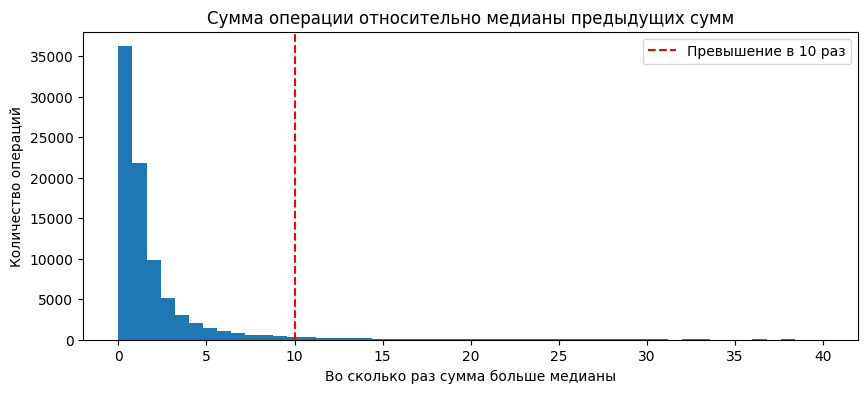

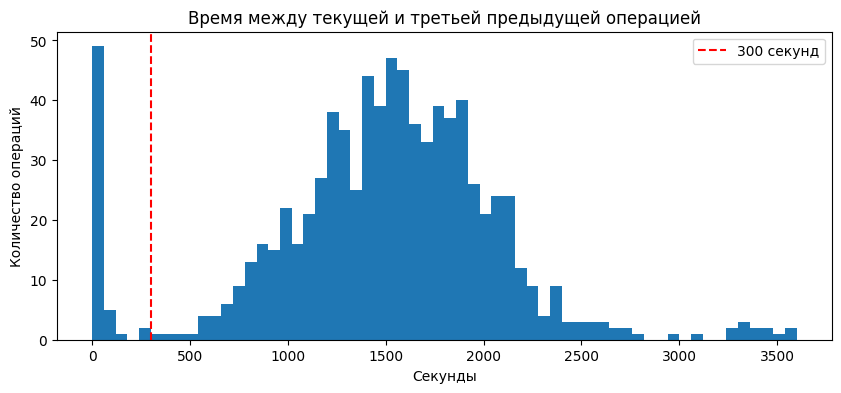

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.hist(eda.loc[eda["has_history"], "amount_/_median"], bins=50, range=(0, 40))
plt.axvline(10, color="red", linestyle="--", label="Превышение в 10 раз")
plt.title("Сумма операции относительно медианы предыдущих сумм")
plt.xlabel("Во сколько раз сумма больше медианы")
plt.ylabel("Количество операций")
plt.legend()
plt.show()

plt.figure(figsize=(10, 4))
plt.hist(eda["seconds_since_third_previous"].dropna(), bins=60, range=(0, 3600))
plt.axvline(300, color="red", linestyle="--", label="300 секунд")
plt.title("Время между текущей и третьей предыдущей операцией")
plt.xlabel("Секунды")
plt.ylabel("Количество операций")
plt.legend()
plt.show()

## Выводы по EDA и аномалиям

- Иностранный IP и ночное время особенно выделяются вместе: доля подтверждений - 28,89%. Среди категорий магазинов самая высокая доля у антиквариата и искусства, причем в обоих магазинах она близкая.
- В покупках полезны новое устройство и частые операции. После хотя бы 3 предыдущих операций за час доля подтверждений - 28,55%, без этого условия - 0,60%.
- В переводах все рассмотренные подтверждения у клиентов с историей пришлись на новых получателей. Но таких переводов много, поэтому одного этого признака недостаточно.
- Сумма относительно привычного уровня клиента сильнее выделяет подтвержденные покупки, чем переводы. При этом в сравнении верхних 10% обычный отбор по сумме нашел больше подтверждений, чем отбор по превышению медианы.
- Без использования меток нашлись 2 930 операций с превышением медианы минимум в 10 раз и 57 операций, перед которыми вместе с текущей было хотя бы 4 операции за 300 секунд. Самый большой скачок среди покупок - 125 496 рублей при медиане предыдущих сумм 191 рубль.



## 2. Построить признак «подозрительности»

Есть подтвержденный фрод и неизвестные операции, поэтому использую PU-bagging на XGBoost.

Выбранные неизвестные временно обозначаются как 0 только внутри отдельного обучения. Надежными обычными операциями они от этого не становятся. Результат использую как балл подозрительности, а не вероятность фрода.

Считаю уже знакомые признаки для всех операций.

In [19]:
data = df.sort_values(["client_id", "ts"], kind="stable").copy()
data["hour"] = data["ts"].dt.hour
data["night"] = data["hour"].isin([1, 2, 3, 4, 5])
data["foreign_ip"] = data["ip_country"] != data["home_country"]
data["past_count"] = data.groupby(["client_id", "type"]).cumcount()
data["past_operations"] = data.groupby("client_id").cumcount()
data["past_median"] = data.groupby(["client_id", "type"])["amount"].transform(lambda x: x.shift().expanding().median())
data["amount_/_median"] = data["amount"] / data["past_median"]
data.loc[data["past_count"] < 3, "amount_/_median"] = np.nan

data["new_device"] = ~data.duplicated(["client_id", "device_id"])
data["new_recipient"] = ~data.duplicated(["client_id", "counterparty_id"])

# Без устройства, получателя или достаточной истории эти сигналы не использую
data["new_device"] = data["new_device"] & data["device_id"].notna() & (data["past_operations"] >= 3)
data["new_recipient"] = data["new_recipient"] & data["counterparty_id"].notna() & (data["past_operations"] >= 3)
previous = data.groupby("client_id")["ts"].shift(3)
data["many_operations"] = (data["ts"] - previous) < pd.Timedelta(hours=1)

Выберу признаки для модели. Неизвестные метки оставляю пустыми.

In [20]:
from xgboost import XGBClassifier

category_columns = ["type", "channel", "status", "segment", "ip_country", "home_country", "mcc_name"]
number_columns = ["amount", "past_median", "amount_/_median", "account_age_months", "hour", "foreign_ip", "past_count", "new_device", "new_recipient", "many_operations", "night"]

X = data[category_columns + number_columns].copy()
for column in category_columns:
    X[column] = X[column].astype("category")
target = data["target"]

Вынесу обучение и расчет оценок в две функции. Число неизвестных в каждом обучении задается относительно числа подтверждений.

In [21]:
def train_pu(X_train, target_train, parameters, bags=30):
    positive = target_train[target_train == 1].index
    unknown = target_train[target_train.isna()].index
    rng = np.random.default_rng(11)
    models = []

    for step in range(bags):
        count = min(len(unknown), len(positive) * parameters["unlabeled_ratio"])
        sample = rng.choice(unknown, size=count, replace=False)
        rows = positive.tolist() + sample.tolist()
        # 0 - временная метка только выбранных неизвестных операций
        answers = [1] * len(positive) + [0] * len(sample)
        model = XGBClassifier(max_depth=parameters["max_depth"], learning_rate=parameters["learning_rate"], n_estimators=parameters["n_estimators"], enable_categorical=True)
        model.fit(X_train.loc[rows], answers)
        models.append(model)

    return models


def predict_pu(models, X):
    score = np.zeros(len(X))
    for model in models:
        score += model.predict_proba(X)[:, 1]
    return score / len(models)

Подберу параметры на данных до 22 октября. Для перебора использую по 5 моделей, для окончательных оценок - по 30. Критерий выбора - средний AP по известным подтверждениям


In [22]:
from sklearn.model_selection import ParameterGrid, TimeSeriesSplit
from sklearn.metrics import average_precision_score

train = data["ts"] < "2026-10-22"
test = data["ts"] >= "2026-10-22"
order = data[train].sort_values("ts").index
X_train = X.loc[order]
target_train = target.loc[order]


parameters = {"max_depth": [3, 5, 10], "learning_rate": [0.01, 0.05, 0.1], "n_estimators": [100, 200, 300], "unlabeled_ratio": [1, 5, 10]}
cv = TimeSeriesSplit(n_splits=3)
best_score = -1

for current in ParameterGrid(parameters):
    scores = []
    for train_rows, valid_rows in cv.split(X_train):
        models = train_pu(X_train.iloc[train_rows], target_train.iloc[train_rows], current, bags=5)
        score = predict_pu(models, X_train.iloc[valid_rows])
        scores.append(average_precision_score(target_train.iloc[valid_rows].notna(), score))
    if np.mean(scores) > best_score:
        best_score = np.mean(scores)
        best_parameters = current.copy()

print("Лучшие параметры:", best_parameters)
print("Средний AP:", round(best_score, 3))

Лучшие параметры: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 200, 'unlabeled_ratio': 5}
Средний AP: 0.257


Теперь проверю выбранные параметры на операциях с 22 октября

In [23]:
models = train_pu(X[train], target[train], best_parameters)
test_result = data.loc[test, ["txn_id", "type", "amount", "target"]].copy()
test_result["suspicion_score"] = predict_pu(models, X[test])
print("Тестовых операций:", len(test_result), "подтверждений:", test_result["target"].count())

Тестовых операций: 40744 подтверждений: 271


Посчитаю, сколько известных подтверждений попало в верхние 1%, 5% и 10% по оценке модели

In [24]:
ordered = test_result.sort_values("suspicion_score", ascending=False)
results = []
for fraction in [0.01, 0.05, 0.10]:
    count = round(len(ordered) * fraction)
    confirmed = ordered.head(count)["target"].count()
    results.append({"check_pct": fraction * 100, "operations": count, "confirmed": confirmed, "capture_pct": confirmed / test_result["target"].count() * 100})

results = pd.DataFrame(results)
print(results.round(2))

   check_pct  operations  confirmed  capture_pct
0        1.0         407        102        37.64
1        5.0        2037        260        95.94
2       10.0        4074        271       100.00


Отдельно посмотрю результат на покупках и переводах.

In [25]:
top = ordered.head(round(len(ordered) * 0.05))

table = test_result.groupby("type")["target"].count().to_frame("confirmed")
table["found"] = top.groupby("type")["target"].sum()
table["capture_pct"] = table["found"] / table["confirmed"] * 100
print(table.round(2))

              confirmed  found  capture_pct
type                                       
purchase            198  192.0        96.97
transfer_out         73   68.0        93.15


Для итогового рейтинга использую 5 OOF-разбиений

In [26]:
from sklearn.model_selection import StratifiedKFold

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=11)
data["suspicion_score"] = np.nan

for train_rows, score_rows in folds.split(X, target.notna()):
    models = train_pu(X.iloc[train_rows], target.iloc[train_rows], best_parameters)
    data.loc[X.index[score_rows], "suspicion_score"] = predict_pu(models, X.iloc[score_rows])

Отдельно выведу подтвержденные и неизвестные операции. Общий список оставлю в ITOG

In [27]:
known_ranking = data[data["target"] == 1].sort_values("suspicion_score", ascending=False)

unknown_ranking = data[data["target"].isna()].sort_values("suspicion_score", ascending=False) # операции со скрытой меткой

print("Известные: ", known_ranking[["txn_id", "type", "amount", "suspicion_score"]].head(50),"\n")
print("Неизвестные: ", unknown_ranking[["txn_id", "type", "amount", "suspicion_score"]].head(50))
print("Неизвестные: ", unknown_ranking[["txn_id", "type", "amount", "suspicion_score"]].tail(50))

ITOG = data.sort_values("suspicion_score", ascending=False) # - итоговые оценки(общие)


Известные:                    txn_id          type  amount  suspicion_score
190202  f40b15e0677e93b9      purchase   14897         0.987445
85315   6d5f8d5d1f8da70e      purchase   33798         0.984243
106942  88f39945cfb90842      purchase   20033         0.981992
131530  a8200fb8c4a9ca8c      purchase   15000         0.976820
128518  a45f49f5fbf4acff      purchase   14000         0.976360
71260   5b52a0105af6c4dd      purchase   22820         0.976106
140878  b40b8cb58c4f94e3  transfer_out   16590         0.975370
162784  d06bc2aa23180762      purchase   69363         0.975218
189270  f2e64b7a71667c2f      purchase   12735         0.973357
72112   5c6ec5160c4c404e      purchase   13000         0.973124
48111   3dbadef7340debd5      purchase   24852         0.973062
111434  8eb219ef779a7d1b      purchase   46534         0.972810
65965   54c10a6a9f248fe2      purchase   47269         0.972059
31730   28a6ad3e42bd08d4      purchase     152         0.972058
78348   6467035b17083080    

## Итоги оценки

На временной проверке PU-bagging охватил 260 из 271 известного подтверждения в верхних 5%, в верхних 10% - 271.

Итоговый рейтинг построен отдельно по OOF-оценкам PU-bagging. Все 199 768 операций находятся в ITOG, рейтинг 198 268 неизвестных - в unknown_ranking. Чем выше балл, тем выше приоритет проверки
